> ✅ **Completed by Ketan Khanna**

> Machine Learning · University of Toronto School of Continuing Studies · Winter 2022 · Week 5

## Assignment for Module 5, Training Models

In this assignment you will train different models on a given data set, and find the one that performs best

### Getting the data for the assignment (similar to the notebook from chapter 2 of Hands-On...)

In [58]:
import os
import tarfile
from six.moves import urllib

DOWNLOAD_ROOT = "data/"
HOUSING_PATH = os.path.join("datasets", "housing")
HOUSING_URL = DOWNLOAD_ROOT + "datasets/housing/housing.tgz"

def fetch_housing_data(housing_url=HOUSING_URL, housing_path=HOUSING_PATH):
    if not os.path.isdir(housing_path):
        os.makedirs(housing_path)
    tgz_path = os.path.join(housing_path, "housing.tgz")
    urllib.request.urlretrieve(housing_url, tgz_path)
    housing_tgz = tarfile.open(tgz_path)
    housing_tgz.extractall(path=housing_path)
    housing_tgz.close()

In [59]:
fetch_housing_data()

In [60]:
import pandas as pd

def load_housing_data(housing_path=HOUSING_PATH):
    csv_path = os.path.join(housing_path, "housing.csv")
    return pd.read_csv(csv_path)

In [61]:
housing = load_housing_data()
housing

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


### Fix the categories in the categorical variable

In [62]:
d = {'<1H OCEAN':'LESS_1H_OCEAN',
     'INLAND':'INLAND',
     'ISLAND':'ISLAND',
     'NEAR BAY':'NEAR_BAY',
     'NEAR OCEAN':'NEAR_OCEAN'}
housing['ocean_proximity'] = housing['ocean_proximity'].map(lambda s: d[s])
housing

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR_BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR_BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR_BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR_BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR_BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


### Add 2 more features

In [63]:
housing["rooms_per_household"] = housing["total_rooms"] / housing["households"]
housing["population_per_household"]=housing["population"] / housing["households"]
housing

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR_BAY,6.984127,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR_BAY,6.238137,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR_BAY,8.288136,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR_BAY,5.817352,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR_BAY,6.281853,2.181467
...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND,5.045455,2.560606
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND,6.114035,3.122807
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND,5.205543,2.325635
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND,5.329513,2.123209


### Fix missing data

In [64]:
median = housing["total_bedrooms"].median()
housing["total_bedrooms"].fillna(median, inplace=True) 

### Create dummy variables based on the categorical variable

In [65]:
one_hot = pd.get_dummies(housing['ocean_proximity'])
housing = housing.drop('ocean_proximity', axis=1)
housing = housing.join(one_hot)

### Check the data

In [66]:
housing.info()
housing["NEAR_BAY"]
housing

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   longitude                 20640 non-null  float64
 1   latitude                  20640 non-null  float64
 2   housing_median_age        20640 non-null  float64
 3   total_rooms               20640 non-null  float64
 4   total_bedrooms            20640 non-null  float64
 5   population                20640 non-null  float64
 6   households                20640 non-null  float64
 7   median_income             20640 non-null  float64
 8   median_house_value        20640 non-null  float64
 9   rooms_per_household       20640 non-null  float64
 10  population_per_household  20640 non-null  float64
 11  INLAND                    20640 non-null  uint8  
 12  ISLAND                    20640 non-null  uint8  
 13  LESS_1H_OCEAN             20640 non-null  uint8  
 14  NEAR_B

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_household,population_per_household,INLAND,ISLAND,LESS_1H_OCEAN,NEAR_BAY,NEAR_OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,6.984127,2.555556,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,6.238137,2.109842,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,8.288136,2.802260,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,5.817352,2.547945,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,6.281853,2.181467,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,5.045455,2.560606,1,0,0,0,0
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,6.114035,3.122807,1,0,0,0,0
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,5.205543,2.325635,1,0,0,0,0
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,5.329513,2.123209,1,0,0,0,0


# ASSIGNMENT

### Q1. Partition into train and test (1 mark)

Use train_test_split from sklearn.model_selection to partition the dataset into 70% for training and 30% for testing.

You can use the 70% for training set as both training and validation by using cross-validation.


In [67]:
from sklearn.model_selection import train_test_split
train_set, test_set = train_test_split(housing, test_size=0.3)
"We have split the training and data set accordingly. For this example I picked 70% for the training set and 30% for the test set"

'We have split the training and data set accordingly. For this example I picked 70% for the training set and 30% for the test set'

Seperating target from features

In [68]:
target = 'median_house_value'
features = list(train_set.columns)
features = [f for f in features if f != target]
features

['longitude',
 'latitude',
 'housing_median_age',
 'total_rooms',
 'total_bedrooms',
 'population',
 'households',
 'median_income',
 'rooms_per_household',
 'population_per_household',
 'INLAND',
 'ISLAND',
 'LESS_1H_OCEAN',
 'NEAR_BAY',
 'NEAR_OCEAN']

In [69]:
# Train set
X_tr = train_set[features]
y_tr = train_set[[target]]

# Test set
X_te = test_set[features]
y_te = test_set[[target]]

In [70]:
X_tr

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,population_per_household,INLAND,ISLAND,LESS_1H_OCEAN,NEAR_BAY,NEAR_OCEAN
7116,-118.01,33.90,36.0,1382.0,257.0,685.0,255.0,5.1250,5.419608,2.686275,0,0,1,0,0
8534,-118.36,33.90,41.0,1355.0,349.0,655.0,329.0,2.9551,4.118541,1.990881,0,0,1,0,0
15228,-117.20,33.07,5.0,10394.0,1617.0,4496.0,1553.0,5.9289,6.692853,2.895042,0,0,0,0,1
144,-122.21,37.80,38.0,2254.0,535.0,951.0,487.0,3.0812,4.628337,1.952772,0,0,0,1,0
874,-122.03,37.56,31.0,4981.0,964.0,2841.0,924.0,4.8962,5.390693,3.074675,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17701,-121.82,37.29,16.0,2085.0,394.0,1705.0,391.0,5.0225,5.332481,4.360614,0,0,1,0,0
10465,-117.76,33.48,38.0,3832.0,809.0,1332.0,636.0,5.0044,6.025157,2.094340,0,0,1,0,0
18821,-120.92,39.56,48.0,1276.0,292.0,358.0,145.0,1.8750,8.800000,2.468966,1,0,0,0,0
13550,-117.30,34.11,42.0,525.0,111.0,444.0,120.0,2.6771,4.375000,3.700000,1,0,0,0,0


In [71]:
y_tr

,median_house_value
7116,211700.0
8534,205000.0
15228,411300.0
144,233100.0
874,220200.0
...,...
17701,222800.0
10465,381200.0
18821,66600.0
13550,67000.0


### Q2. Polynomial transformations (1 mark)

Use PolynomialFeatures from sklearn.preprocessing to add higher degree features (degree=2).

In [72]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2)
poly.fit(X_tr)
X = poly.fit_transform(X_tr)
pd.DataFrame(X)
X_tr = pd.DataFrame(poly.fit_transform(X_tr)) 
X_te = pd.DataFrame(poly.fit_transform(X_te))

"Used polynomialfeatures to add a higher degree feature"

'Used polynomialfeatures to add a higher degree feature'

You should obtain X_tr and X_te with 136 columns each, since originally you had 15 features.

With m original features, the new added polynomial features of degree 2 are: $(m^2-m)/2+m+1$. Why?

These, plus the original features gives a total of  $(m^2-m)/2+2m+1$

In [73]:
print("Original number of features: " + str(len(features)))
print("Final number of features: " + str(X_tr.shape[1]))

"Indeed obtaining an X_tr and X+te with 136 columns"

Original number of features: 15
Final number of features: 136


'Indeed obtaining an X_tr and X+te with 136 columns'

In [74]:
X_tr

,0,1,2,3,4,5,6,7,8,9,...,126,127,128,129,130,131,132,133,134,135
0,1.0,-118.01,33.90,36.0,1382.0,257.0,685.0,255.0,5.1250,5.419608,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,1.0,-118.36,33.90,41.0,1355.0,349.0,655.0,329.0,2.9551,4.118541,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,1.0,-117.20,33.07,5.0,10394.0,1617.0,4496.0,1553.0,5.9289,6.692853,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.0,-122.21,37.80,38.0,2254.0,535.0,951.0,487.0,3.0812,4.628337,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.0,-122.03,37.56,31.0,4981.0,964.0,2841.0,924.0,4.8962,5.390693,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14443,1.0,-121.82,37.29,16.0,2085.0,394.0,1705.0,391.0,5.0225,5.332481,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
14444,1.0,-117.76,33.48,38.0,3832.0,809.0,1332.0,636.0,5.0044,6.025157,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
14445,1.0,-120.92,39.56,48.0,1276.0,292.0,358.0,145.0,1.8750,8.800000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
14446,1.0,-117.30,34.11,42.0,525.0,111.0,444.0,120.0,2.6771,4.375000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Q3. Scaling features (1 mark)

Similarly, use StandardScaler from sklearn.preprocessing to normalize the training and testing data, using the training data

In [75]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_tr)
X_tr = pd.DataFrame(scaler.transform(X_tr))
scaler.fit(X_te)
X_te = pd.DataFrame(scaler.transform(X_te))
scaler.fit(y_tr)
y_tr = pd.DataFrame(scaler.transform(y_tr))
scaler.fit(y_te)
y_te = pd.DataFrame(scaler.transform(y_te))

"Scaling down the data for simplicity of analysis and to enable less computing power during run time"

'Scaling down the data for simplicity of analysis and to enable less computing power during run time'

In [76]:
X_tr

,0,1,2,3,4,5,6,7,8,9,...,126,127,128,129,130,131,132,133,134,135
0,0.0,0.771342,-0.804794,0.587223,-0.573923,-0.665382,-0.646104,-0.637443,0.671367,-0.009210,...,-0.014411,0.0,0.0,0.0,1.119655,0.0,0.0,-0.349410,0.0,-0.387591
1,0.0,0.596448,-0.804794,0.983539,-0.586165,-0.448938,-0.672101,-0.446423,-0.483473,-0.492463,...,-0.014411,0.0,0.0,0.0,1.119655,0.0,0.0,-0.349410,0.0,-0.387591
2,0.0,1.176098,-1.194225,-1.869942,3.512440,2.534226,2.656415,2.713142,1.099209,0.463710,...,-0.014411,0.0,0.0,0.0,-0.893133,0.0,0.0,-0.349410,0.0,2.580038
3,0.0,-1.327388,1.025063,0.745749,-0.178527,-0.011344,-0.415594,-0.038571,-0.416361,-0.303110,...,-0.014411,0.0,0.0,0.0,-0.893133,0.0,0.0,2.861964,0.0,-0.387591
4,0.0,-1.237443,0.912456,0.190906,1.057992,0.997944,1.222233,1.089476,0.549598,-0.019950,...,-0.014411,0.0,0.0,0.0,-0.893133,0.0,0.0,2.861964,0.0,-0.387591
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14443,0.0,-1.132506,0.785774,-0.998045,-0.255157,-0.343068,0.237803,-0.286380,0.616815,-0.041571,...,-0.014411,0.0,0.0,0.0,1.119655,0.0,0.0,-0.349410,0.0,-0.387591
14444,0.0,0.896267,-1.001855,0.745749,0.536995,0.633282,-0.085429,0.346049,0.607182,0.215708,...,-0.014411,0.0,0.0,0.0,1.119655,0.0,0.0,-0.349410,0.0,-0.387591
14445,0.0,-0.682778,1.850844,1.538383,-0.621987,-0.583039,-0.929474,-0.921391,-1.058311,1.246364,...,-0.014411,0.0,0.0,0.0,-0.893133,0.0,0.0,-0.349410,0.0,-0.387591
14446,0.0,1.126128,-0.706263,1.062803,-0.962517,-1.008869,-0.854948,-0.985924,-0.631427,-0.397207,...,-0.014411,0.0,0.0,0.0,-0.893133,0.0,0.0,-0.349410,0.0,-0.387591


For comparing models

In [77]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
import numpy as np

def display_scores(scores):
    print("Scores:", scores)
    print("Mean:", scores.mean())

### Q4. Linear regression on original features (no transformations) -- benchmark only (0 marks)

Your goal is to find the model that minimizes the rmse score

In [78]:
from sklearn.linear_model import LinearRegression

lin_scores = cross_val_score(LinearRegression(),
                             train_set[features],
                             train_set[target],
                             scoring="neg_mean_squared_error",
                             cv=4)
lin_rmse_scores = np.sqrt(-lin_scores)
display_scores(lin_rmse_scores)

Scores: [ 72133.45049121 110483.80132575  66458.22314327  68731.00676936]
Mean: 79451.6204323943


### Q5. Linear regression on transformed features -- polynomial transformation + scaling (2 marks)

Now do as in Q4 but with the transformed features (136 features)

In [79]:
lin_scores = cross_val_score(LinearRegression(),
                             X_tr,
                             y_tr,
                             scoring="neg_mean_squared_error",
                             cv=4)
#lin_scores
lin_rmse_scores = np.sqrt(-lin_scores)
display_scores(lin_rmse_scores)

Scores: [2.35472211e+08 6.62747701e+01 9.26734793e+10 1.15697186e+00]
Mean: 23227237906.287918


If the error on the cross-validation is too high it is because the model is over-fitting. Regularization is needed.

### Q6. Ridge regression -- benchmark only (0 marks)

In [80]:
from sklearn.linear_model import Ridge

param_grid = [{'alpha': [0.001,0.01,0.1,1,10,100,1000,1000]}]
grid_search_rr = GridSearchCV(Ridge(), param_grid, cv=3, scoring='neg_mean_squared_error')
grid_search_rr.fit(X_tr, y_tr)

GridSearchCV(cv=3, estimator=Ridge(),
             param_grid=[{'alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000, 1000]}],
             scoring='neg_mean_squared_error')

In [81]:
print(grid_search_rr.best_params_)
print(np.sqrt(-grid_search_rr.best_score_))

{'alpha': 1000}
0.5760461794102196


### Q7. Lasso regression (2 marks)

Now do the same as in Q6 but with Lasso

In [82]:
from sklearn.linear_model import Lasso
param_grid = [{'alpha': [0.001,0.01,0.1,1,10,100,1000,1000]}]
grid_search_lr = GridSearchCV(Lasso(), param_grid, cv=3, scoring='neg_mean_squared_error')
grid_search_lr.fit(X_tr, y_tr)
GridSearchCV(cv=3, estimator=Lasso(),
             param_grid=[{'alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000, 1000]}],
             scoring='neg_mean_squared_error')
print(grid_search_lr.best_params_)
print(np.sqrt(-grid_search_lr.best_score_))

C:\Users\user\anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:530: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 14.255983091762573, tolerance: 0.9455618870877527
  model = cd_fast.enet_coordinate_descent(
C:\Users\user\anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:530: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 77.91607590213744, tolerance: 0.9727290866364534
  model = cd_fast.enet_coordinate_descent(
C:\Users\user\anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:530: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 6.275039243290848, tolerance: 0.9712811328800505
  model = cd_fast.enet_coordinate_descent(


{'alpha': 0.01}
0.580567741290915


### Q8. Elastic Net regression (2 marks)

Do the same as in 6 and 7, but now with Elastic Net. However, the grid search should be over the parameters alpha and  l1ratio. Use just 3 values for l1_ratio.

In [83]:
from sklearn.linear_model import ElasticNet
param_grid = [{'alpha': [0.001,0.01,0.1,1,10,100,1000,1000]}]
grid_search_enr = GridSearchCV(ElasticNet(), param_grid, cv=3, scoring='neg_mean_squared_error')
grid_search_enr.fit(X_tr, y_tr)
GridSearchCV(cv=3, estimator=ElasticNet(),
             param_grid=[{'alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000, 1000]}],
             scoring='neg_mean_squared_error')
print(grid_search_enr.best_params_)
print(np.sqrt(-grid_search_enr.best_score_))

"Abided by the parameters set forth, grid search is over the alpha and l1ratio"

C:\Users\user\anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:530: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 102.8144658816218, tolerance: 0.9455618870877527
  model = cd_fast.enet_coordinate_descent(
C:\Users\user\anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:530: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 85.65795855723945, tolerance: 0.9727290866364534
  model = cd_fast.enet_coordinate_descent(
C:\Users\user\anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:530: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 146.05311122977605, tolerance: 0.9712811328800505
  model = cd_fast.enet_coordinate_descent(
C:\Users\user\anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:530: ConvergenceWarnin

{'alpha': 0.01}
0.5718526511425309


C:\Users\user\anaconda3\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:530: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 1.7954341679960635, tolerance: 1.4448
  model = cd_fast.enet_coordinate_descent(


'Abided by the parameters set forth, grid search is over the alpha and l1ratio'

Evaluating your best model on TESTING data

Choose among grid_search_rr, grid_search_lr, and grid_search_enr, the model with best performance

In [84]:
from sklearn.metrics import mean_squared_error

final_model = grid_search_rr # best estimator is estimator with more cross validation score
 
y_te_estimation = final_model.predict(X_te)

final_mse = mean_squared_error(y_te, y_te_estimation)
final_rmse = np.sqrt(final_mse)
print(final_rmse)

"grid_search_rr chosen as the best model for performance"

0.5764031378936368


'grid_search_rr chosen as the best model for performance'

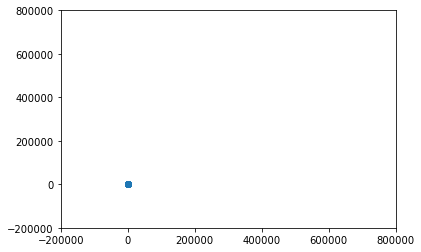

In [85]:
import matplotlib.pyplot as plt

plt.scatter(x=y_te, y=y_te_estimation)
plt.xlim([-200000,800000])
plt.ylim([-200000,800000])
plt.show()

### Q9. Before you computed the final_rmse on the test data, what was your expected value for this quantity? Does your best model have high variance? (1 mark)

##### YOUR ANSWER HERE 

In [86]:
"""Expected value for rmse was approximately the same before computing for the final_rmse. Though the model could have slightly
better variance, I would still consider it acceptable in this scenario"""

'Expected value for rmse was approximately the same before computing for the final_rmse. Though the model could have slightly\nbetter variance, I would still consider it acceptable in this scenario'